# Gradient Boosted Trees (XGBoost)

This notebook builds and tunes a gradient boosted tree model to predict whether a booking will be cancelled. It uses `hotel_bookings_clean.csv` and the train/validation/test split from `02-Preprocessing`.

## 1. Why gradient boosted trees?

The EDA in `01-Introduction` showed three things about this data that shaped the choice of model:

* **Non-linear effects.** The cancellation rate rises steeply with lead time over the first few months and then levels off.
* **Interactions.** The same feature means different things in different contexts: for example, the city hotel cancels much more than the resort hotel at every lead time, and non-refundable deposits are concentrated in group and tour-operator bookings at the city hotel.
* **Mostly categorical features.** Deposit type, market segment, country, agent and customer type all matter.

A logistic regression is linear in the log-odds, so non-linear effects and interactions have to be added by hand. Decision trees capture both automatically, because each split can depend on the splits above it. A single tree, however, is unstable and either too simple or overfits. Ensembles of trees fix this in two ways:

* **Random forests** (bagging) average many deep, independently grown trees. Averaging mainly reduces *variance*.
* **Gradient boosting** adds shallow trees one at a time, each one correcting the errors of those before it. This mainly reduces *bias*, and with regularisation it typically gives the most accurate models on tabular data like ours ([Grinsztajn, Oyallon & Varoquaux, 2022](https://arxiv.org/abs/2207.08815)).

We use **XGBoost** ([Chen & Guestrin, 2016](https://doi.org/10.1145/2939672.2939785)), which adds explicit regularisation to gradient boosting and is fast enough to tune on over 80,000 bookings on a laptop. Trees also need no feature scaling and are unaffected by monotone transformations of a feature, which saves preprocessing.

The main drawbacks are that the model is harder to interpret than a logistic regression, it has many hyperparameters, and its predicted probabilities are not guaranteed to be well calibrated. We address each of these below.

## 2. How XGBoost works

### 2.1 The model

A regression tree $f$ splits the feature space into $T$ regions (leaves) and assigns each leaf a weight $w_j$. Writing $q(x)$ for the leaf that booking $x$ falls into, $f(x) = w_{q(x)}$.

The boosted model adds up $M$ trees to give a score on the log-odds scale, which is turned into a probability with the logistic function $\sigma$:

$$F_M(x) = \sum_{m=1}^{M} \eta\, f_m(x), \qquad \hat p(x) = \sigma\big(F_M(x)\big) = \frac{1}{1 + e^{-F_M(x)}},$$

where $\eta \in (0, 1]$ is the **learning rate** (shrinkage). We train with the log-loss (binary cross-entropy), the negative log-likelihood of a Bernoulli outcome:

$$\ell(y, F) = -\big[y \log \sigma(F) + (1 - y)\log\big(1 - \sigma(F)\big)\big].$$

### 2.2 Fitting one tree at a time

Trees are added greedily. At round $m$, the trees so far are fixed and the new tree $f_m$ is chosen to minimise a regularised objective:

$$\mathcal{L}^{(m)} = \sum_{i=1}^{n} \ell\big(y_i, F_{m-1}(x_i) + f_m(x_i)\big) + \Omega(f_m), \qquad \Omega(f) = \gamma T + \tfrac{1}{2}\lambda \sum_{j=1}^{T} w_j^2.$$

The penalty $\Omega$ is what distinguishes XGBoost from earlier gradient boosting ([Friedman, 2001](https://doi.org/10.1214/aos/1013203451)): $\gamma$ charges for every extra leaf, and $\lambda$ shrinks leaf weights towards zero.

XGBoost approximates the loss with a second-order Taylor expansion around the current prediction. For the log-loss the first and second derivatives with respect to $F$ are simple:

$$g_i = \hat p_i - y_i, \qquad h_i = \hat p_i\,(1 - \hat p_i).$$

So $g_i$ is the current error on booking $i$, and $h_i$ measures how uncertain the model still is about it. Dropping constant terms, the objective becomes a sum over leaves. Writing $G_j = \sum_{i \in \text{leaf } j} g_i$ and $H_j = \sum_{i \in \text{leaf } j} h_i$,

$$\tilde{\mathcal{L}}^{(m)} = \sum_{j=1}^{T}\Big[G_j w_j + \tfrac{1}{2}(H_j + \lambda)\,w_j^2\Big] + \gamma T.$$

Each bracket is a quadratic in $w_j$, so the best leaf weight and the resulting objective are

$$w_j^* = -\frac{G_j}{H_j + \lambda}, \qquad \tilde{\mathcal{L}}^* = -\frac{1}{2}\sum_{j=1}^{T}\frac{G_j^2}{H_j + \lambda} + \gamma T.$$

### 2.3 Choosing splits

A leaf is split into left and right children only if this reduces the objective. The reduction is the **gain**:

$$\text{Gain} = \frac{1}{2}\left[\frac{G_L^2}{H_L + \lambda} + \frac{G_R^2}{H_R + \lambda} - \frac{(G_L + G_R)^2}{H_L + H_R + \lambda}\right] - \gamma.$$

A split is made only if the gain is positive, so $\gamma$ acts as a minimum improvement, and larger $\lambda$ makes every split look less attractive. This formula is how each regularisation hyperparameter in Section 4 enters the model.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.metrics import log_loss, roc_auc_score, brier_score_loss, accuracy_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


## 3. Preparing the data

We load the clean data and select features.

* **Excluded:** `arrival_date` and `arrival_date_year`. As noted in `02-Preprocessing`, the hotel would use the model on bookings in future years, so anything the model learned about specific years would not carry over.
* **Categorical features** are one-hot encoded. Trees could split on integer codes instead, but that would impose an arbitrary order on categories such as country.
* **No scaling.** Splits depend only on the order of a feature's values, so scaling makes no difference to a tree.
* **No class reweighting.** 37% of bookings are cancelled, so the classes are not badly imbalanced. Reweighting (for example with XGBoost's `scale_pos_weight`) would also push the predicted probabilities away from the true cancellation rates, and the hotel needs those probabilities to be accurate.

In [2]:
df = pd.read_csv("hotel_bookings_clean.csv", keep_default_na=False, na_values=[""])
df["agent"] = df["agent"].astype(str)
TARGET = "is_canceled"

CATEGORICAL = ["hotel", "arrival_date_month", "meal", "country", "market_segment",
               "distribution_channel", "reserved_room_type", "deposit_type", "agent", "customer_type"]
NOT_FEATURES = [TARGET, "split", "arrival_date", "arrival_date_year"]

def make_features(data, drop=()):
    X = data.drop(columns=NOT_FEATURES + list(drop))
    return pd.get_dummies(X, columns=[c for c in CATEGORICAL if c in X.columns], dtype=float)

y = df[TARGET]
is_train, is_val, is_test = (df.split == s for s in ["train", "validation", "test"])
print(f"Train: {is_train.sum():,}   Validation: {is_val.sum():,}   Test: {is_test.sum():,}")

Train: 83,324   Validation: 17,331   Test: 17,903


### 3.1 Validation strategy

We tune on the **validation set** (a random 15% of bookings, with copies of a booking kept in the same set, as described in `02-Preprocessing`) and touch the test set only once, at the very end.

Because the split is random, $k$-fold cross-validation on the training set would also be valid, and would average out some noise. We use the single validation set instead because it is large (over 17,000 bookings, so scores are stable to about the third decimal place), it is the same for every group member, and it makes each fit five times cheaper, which lets us try more settings.

We use **validation log-loss** to compare settings. It is the quantity the model is trained to minimise, and, unlike accuracy or AUC, it rewards probabilities that are both well ranked and at the right level. We report AUC alongside it. The group's agreed performance metric is applied to every model in the metrics and comparison notebooks.

**Early stopping.** Every fit below adds trees until validation log-loss has not improved for 50 rounds, then keeps the best number of trees. This tunes the number of trees $M$ automatically for each setting.

### 3.2 Should the arrival month be a feature?

The EDA showed seasonal patterns in cancellations, so the arrival month and week number look like natural features. They also carry a risk: the data covers only about two years, so the model can only learn the seasonal pattern of *those* years, and Figure 5 in `01-Introduction` showed this pattern changing from one year to the next.

We compare three feature sets with otherwise default settings.

In [3]:
def fit_xgb(X_tr, y_tr, X_va, y_va, learning_rate=0.1, **params):
    model = xgb.XGBClassifier(n_estimators=3000, learning_rate=learning_rate, tree_method="hist",
                              early_stopping_rounds=50, eval_metric="logloss",
                              random_state=RANDOM_STATE, n_jobs=-1, **params)
    model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    return model

options = {"All features": (),
           "Without week number": ("arrival_date_week_number",),
           "Without week number or month": ("arrival_date_week_number", "arrival_date_month")}
rows = []
for name, drop in options.items():
    X = make_features(df, drop)
    m = fit_xgb(X[is_train], y[is_train], X[is_val], y[is_val])
    p = m.predict_proba(X[is_val])[:, 1]
    rows.append({"features": name, "columns": X.shape[1], "trees (early stopping)": m.best_iteration + 1,
                 "val log-loss": log_loss(y[is_val], p), "val AUC": roc_auc_score(y[is_val], p)})
pd.DataFrame(rows).set_index("features").round(4)

,columns,trees (early stopping),val log-loss,val AUC
features,,,,
All features,187,271,0.3304,0.9220
Without week number,186,288,0.3331,0.9205
Without week number or month,174,256,0.3357,0.9191


Keeping both date features gives the best result: validation log-loss is 0.330, against 0.336 without them, and AUC is 0.922 against 0.919. The gain is small but consistent, so we **keep the arrival month and week number**.

This comes with a caveat that the random split can't test. The validation bookings come from the same years and seasons as the training bookings, so the comparison rewards a model for learning *those years'* seasonal pattern. Whether the pattern holds in a future year is a different question. In an earlier version of this analysis we used a time-based split (training on 2015–16, validating on late 2016), and there the same features made the model *worse* (log-loss 0.451 against 0.412), because the seasonal pattern changed between years. If the hotel used this model on next year's bookings, the date features would be the first thing to re-check.

In [4]:
X = make_features(df)
X_train, y_train = X[is_train], y[is_train]
X_val, y_val = X[is_val], y[is_val]
X_test, y_test = X[is_test], y[is_test]
print(f"{X.shape[1]} feature columns after one-hot encoding")

187 feature columns after one-hot encoding


## 4. Tuning the hyperparameters

### 4.1 What each hyperparameter does

| Hyperparameter | Role | Effect of increasing it |
| --- | --- | --- |
| `learning_rate` ($\eta$) | Shrinks each tree's contribution | Faster learning, but each tree can overshoot, so usually worse final accuracy |
| `n_estimators` ($M$) | Number of trees | Set by early stopping |
| `max_depth` | Maximum depth of each tree | Allows higher-order interactions, but more risk of overfitting |
| `min_child_weight` | Minimum $H_j = \sum h_i$ in a leaf | Leaves need more (uncertain) bookings, so fewer, more reliable splits |
| `gamma` ($\gamma$) | Minimum gain for a split (Section 2.3) | Fewer splits; prunes weak branches |
| `reg_lambda` ($\lambda$) | L2 penalty on leaf weights | Shrinks $w_j^* = -G_j/(H_j+\lambda)$ towards zero |
| `subsample` | Share of bookings sampled for each tree | Lower values add randomness that reduces variance ([Friedman, 2002](https://doi.org/10.1016/S0167-9473(01)00065-2)) |
| `colsample_bytree` | Share of features sampled for each tree | Lower values decorrelate the trees, as in a random forest |

Since $h_i = \hat p_i(1 - \hat p_i) \le 1/4$, `min_child_weight` $= 5$ means a leaf must contain at least 20 bookings, and more when the model is already confident about them.

### 4.2 Search strategy

We tune in two stages:

1. **Random search** over the tree-structure and regularisation parameters, with a fixed, fairly high learning rate of 0.1 to keep each fit fast. Random search explores many values of each parameter for the same budget, and is more efficient than a grid when only a few parameters really matter ([Bergstra & Bengio, 2012](https://www.jmlr.org/papers/v13/bergstra12a.html)). We try 30 settings.
2. **Lower the learning rate** to 0.03 with the best settings and let early stopping choose the (larger) number of trees. Smaller steps generally generalise better, at the cost of more trees ([Friedman, 2001](https://doi.org/10.1214/aos/1013203451)).

In [5]:
rng = np.random.default_rng(RANDOM_STATE)
search_space = {
    "max_depth":        lambda: int(rng.choice([3, 4, 5, 6, 8, 10])),
    "min_child_weight": lambda: float(rng.choice([1, 3, 5, 10, 20])),
    "gamma":            lambda: float(rng.choice([0, 0.1, 0.5, 1, 2])),
    "reg_lambda":       lambda: float(10 ** rng.uniform(-1, 1)),     # 0.1 to 10, log scale
    "subsample":        lambda: float(rng.uniform(0.6, 1.0)),
    "colsample_bytree": lambda: float(rng.uniform(0.5, 1.0)),
}

results = []
start = time.time()
for trial in range(30):
    params = {name: draw() for name, draw in search_space.items()}
    m = fit_xgb(X_train, y_train, X_val, y_val, learning_rate=0.1, **params)
    p = m.predict_proba(X_val)[:, 1]
    results.append({**params, "trees": m.best_iteration + 1,
                    "val_logloss": log_loss(y_val, p), "val_auc": roc_auc_score(y_val, p)})
results = pd.DataFrame(results).sort_values("val_logloss").reset_index(drop=True)
results.head(8).round(3)

30 settings tried in 407 seconds


,max_depth,min_child_weight,gamma,reg_lambda,subsample,colsample_bytree,trees,val_logloss,val_auc
0,10,5.0,0.5,7.137,0.858,0.911,220,0.321,0.927
1,5,5.0,0.5,0.216,0.609,0.545,682,0.321,0.927
2,6,5.0,2.0,3.604,0.678,0.733,491,0.321,0.927
3,8,10.0,1.0,0.839,0.665,0.751,195,0.322,0.927
4,5,10.0,1.0,1.797,0.834,0.825,616,0.322,0.926
5,8,3.0,0.0,2.172,0.788,0.783,228,0.322,0.926
6,10,3.0,1.0,2.715,0.780,0.636,200,0.322,0.926
7,5,5.0,0.5,0.285,0.822,0.532,614,0.323,0.926


Figure 1 shows the validation log-loss of every setting against each hyperparameter, to see which ones matter.

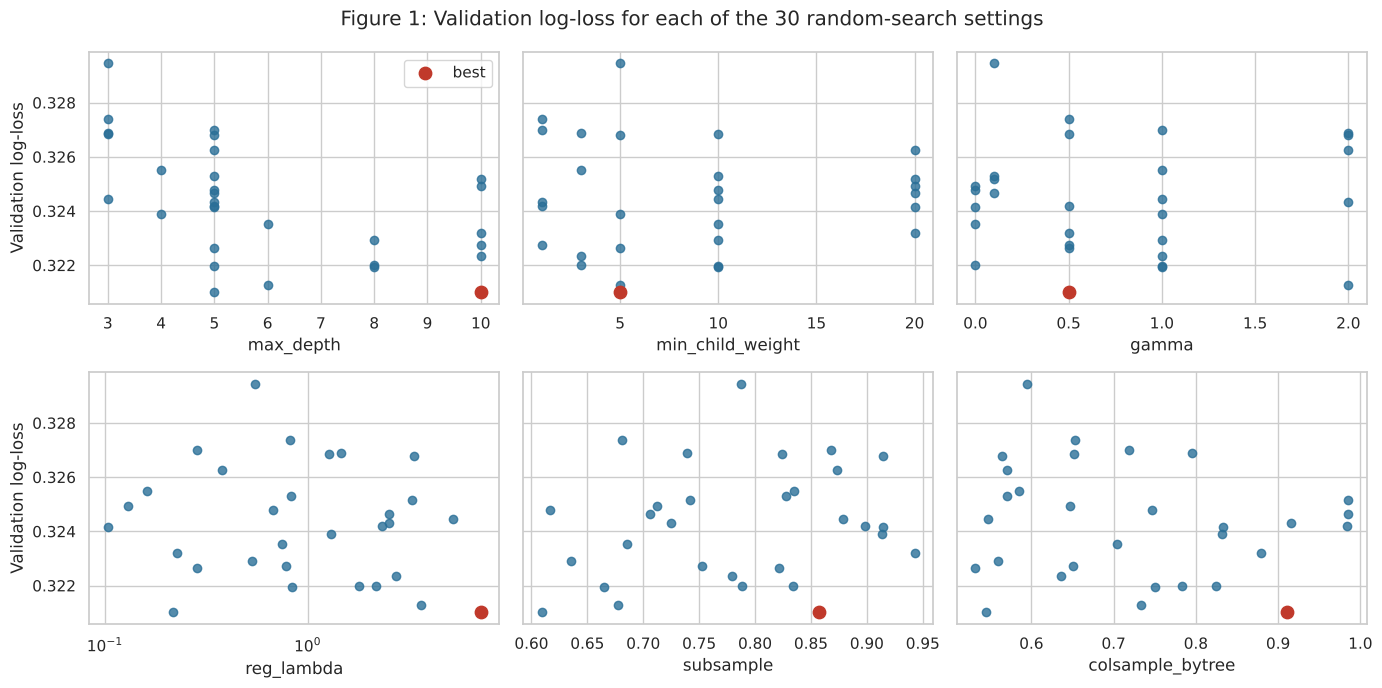

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
for ax, name in zip(axes.flat, search_space):
    ax.scatter(results[name], results.val_logloss, color="#2a6f97", alpha=0.8)
    ax.scatter(results.loc[0, name], results.loc[0, "val_logloss"], color="#c0392b", s=80, label="best")
    ax.set_xlabel(name)
    if name == "reg_lambda":
        ax.set_xscale("log")
for ax in axes[:, 0]:
    ax.set_ylabel("Validation log-loss")
axes[0, 0].legend()
fig.suptitle("Figure 1: Validation log-loss for each of the 30 random-search settings")
plt.tight_layout()
plt.show()

The 30 settings all score between 0.321 and 0.329, a narrow range. The model is fairly robust to its hyperparameters, and the top eight settings differ by less than 0.002, which is close to the noise of a single validation set. We shouldn't read too much into the exact values chosen.

Some patterns are still clear:

* **Very shallow trees do worst.** Every setting with `max_depth` $= 3$ scores 0.324 or worse. Cancellation depends on interactions between several features, which shallow trees can only build up slowly.
* **Depth and number of trees trade off.** Deep trees (depth 8 to 10) reach their best score after about 200 trees, while depth-5 trees need about 600. Each deep tree captures more interactions at once, so fewer are needed.
* **Deep trees need regularising.** The best setting combines `max_depth` $= 10$ with a large L2 penalty ($\lambda = 7.1$) and a minimum split gain of $\gamma = 0.5$. By the formulas in Section 2, these shrink each leaf weight and block splits that don't improve the objective enough, which stops the deep trees from fitting noise.

### 4.3 Lowering the learning rate

We now refit the best setting with $\eta = 0.03$. Figure 2 shows the training and validation log-loss as trees are added. Training loss keeps falling, because each tree fits the training data a little better, while validation loss flattens and then starts to rise once the model begins to fit noise. Early stopping picks the point where validation loss is lowest.

Best settings: {'max_depth': 10, 'min_child_weight': 5.0, 'gamma': 0.5, 'reg_lambda': 7.137, 'subsample': 0.858, 'colsample_bytree': 0.911}
Trees chosen by early stopping: 797
Validation log-loss: 0.3196  (search best at eta = 0.1: 0.3210)
Validation AUC:      0.9277


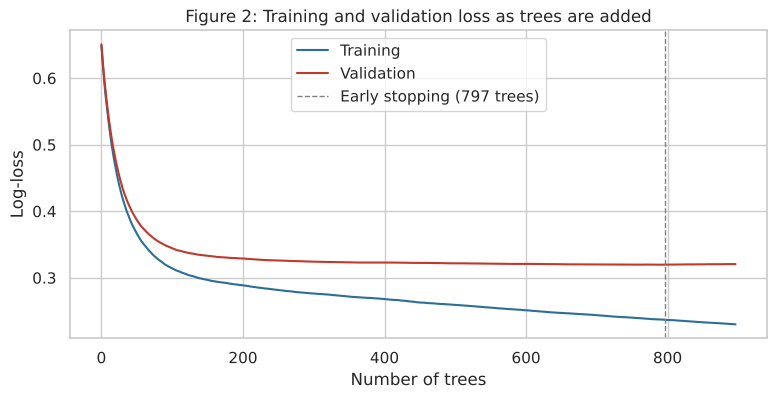

In [7]:
best_params = results.loc[0, list(search_space)].to_dict()
best_params["max_depth"] = int(best_params["max_depth"])

final = xgb.XGBClassifier(n_estimators=5000, learning_rate=0.03, tree_method="hist",
                          early_stopping_rounds=100, eval_metric="logloss",
                          random_state=RANDOM_STATE, n_jobs=-1, **best_params)
final.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_val, y_val)], verbose=False)
n_trees = final.best_iteration + 1

p_val = final.predict_proba(X_val, iteration_range=(0, n_trees))[:, 1]
print("Best settings:", {k: round(v, 3) if isinstance(v, float) else v for k, v in best_params.items()})
print(f"Trees chosen by early stopping: {n_trees}")
print(f"Validation log-loss: {log_loss(y_val, p_val):.4f}  (search best at eta = 0.1: {results.loc[0, 'val_logloss']:.4f})")
print(f"Validation AUC:      {roc_auc_score(y_val, p_val):.4f}")

curves = final.evals_result()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(curves["validation_0"]["logloss"], label="Training", color="#2a6f97")
ax.plot(curves["validation_1"]["logloss"], label="Validation", color="#c0392b")
ax.axvline(n_trees - 1, color="grey", ls="--", lw=1, label=f"Early stopping ({n_trees} trees)")
ax.set_xlabel("Number of trees")
ax.set_ylabel("Log-loss")
ax.set_title("Figure 2: Training and validation loss as trees are added")
ax.legend()
plt.show()

Lowering the learning rate to 0.03 gives a small further gain: validation log-loss falls from 0.3210 to 0.3196, using 797 trees instead of about 220. Figure 2 shows the typical shape. Training loss keeps falling as trees are added, while validation loss falls quickly over the first 200 trees and then improves only very slowly. The growing gap between the two curves shows the model starting to fit details of the training data that don't carry over, and early stopping ends training before this makes the validation loss worse.

## 5. Checking the model

### 5.1 Calibration

For the hotel, the predicted probabilities matter, not just the ranking of bookings: the number of rooms to overbook depends on how many cancellations are expected. A model is **calibrated** if, among bookings given probability $p$, a proportion $p$ actually cancel. Figure 3 is a reliability diagram on the validation set: predictions are grouped into ten bins, and the observed cancellation rate in each bin is plotted against the average prediction.

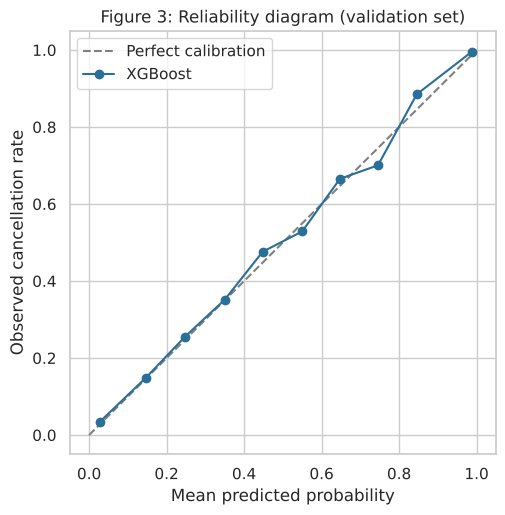

Mean predicted probability: 37.0%   Actual cancellation rate: 37.5%


In [8]:
bins = pd.cut(p_val, np.linspace(0, 1, 11), include_lowest=True)
rel = pd.DataFrame({"p": p_val, "y": y_val.to_numpy()}).groupby(bins, observed=True).agg(
    predicted=("p", "mean"), observed=("y", "mean"), bookings=("y", "size"))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], ls="--", color="grey", label="Perfect calibration")
ax.plot(rel.predicted, rel.observed, marker="o", color="#2a6f97", label="XGBoost")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed cancellation rate")
ax.set_title("Figure 3: Reliability diagram (validation set)")
ax.legend()
plt.show()
print(f"Mean predicted probability: {p_val.mean():.1%}   Actual cancellation rate: {y_val.mean():.1%}")

The points lie close to the diagonal, so the model is **well calibrated**. On average it predicts a 37.0% chance of cancellation, against an actual rate of 37.5%, and the largest gaps, of up to 4.5 percentage points, are in the middle bins between 0.4 and 0.9, which contain fewer bookings. No recalibration is needed.

This is partly a consequence of the random split: the validation bookings come from the same mix of periods as the training bookings. On genuinely new data, from a later year, calibration would need checking again.

### 5.2 Which features does the model use?

Gradient boosting is harder to interpret than a logistic regression, because a feature's effect is spread across hundreds of trees. We use **SHAP values** ([Lundberg & Lee, 2017](https://arxiv.org/abs/1705.07874)), which split each prediction into a contribution from each feature, based on the Shapley value from game theory. For a booking $x$,

$$F(x) = \phi_0 + \sum_{k} \phi_k(x),$$

where $\phi_0$ is the average log-odds and $\phi_k(x)$ is feature $k$'s contribution for that booking. XGBoost computes these exactly for trees ([Lundberg et al., 2020](https://doi.org/10.1038/s42256-019-0138-9)). We average $|\phi_k|$ over the validation set, and add up the one-hot columns that came from the same original feature.

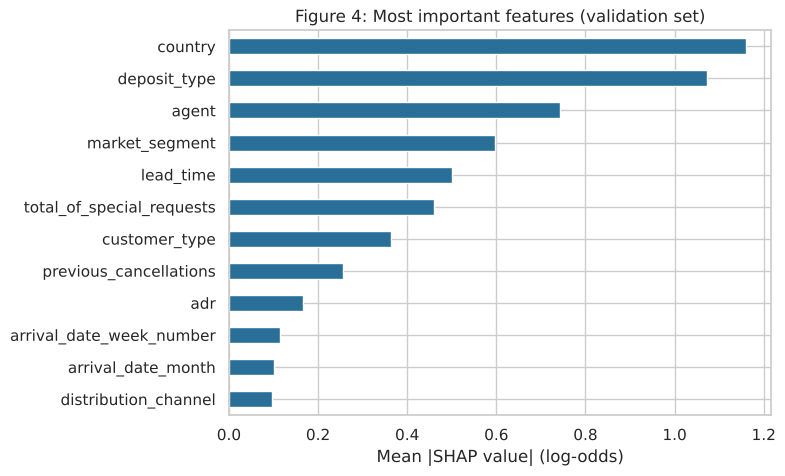

In [9]:
contribs = final.get_booster().predict(xgb.DMatrix(X_val), pred_contribs=True,
                                       iteration_range=(0, n_trees))[:, :-1]   # last column is phi_0
shap_abs = pd.Series(np.abs(contribs).mean(axis=0), index=X_val.columns)
original = shap_abs.index.map(lambda c: next((cat for cat in CATEGORICAL if c.startswith(cat + "_")), c))
importance = shap_abs.groupby(original).sum().sort_values()

ax = importance.tail(12).plot(kind="barh", color="#2a6f97", figsize=(7, 5))
ax.set_xlabel("Mean |SHAP value| (log-odds)")
ax.set_title("Figure 4: Most important features (validation set)")
plt.show()

The model relies most on **country**, **deposit type** and **agent**, followed by market segment, lead time, special requests, customer type and previous cancellations. This matches the EDA in `01-Introduction`. The arrival month and week number contribute, but much less than the booking's own characteristics.

Lead time ranks lower than the EDA might suggest. This is because it is correlated with deposit type and market segment (group and tour-operator bookings are made far in advance), and SHAP shares the credit between correlated features. Two cautions:

* SHAP values explain what the model uses, not what *causes* cancellations.
* Deposit type is near the top, and its non-refundable category behaves surprisingly (almost all such bookings are cancelled). If the hotels changed how they record these bookings, the model's predictions would change sharply.

## 6. Final model and test-set results

The final model is the tuned model from Section 4.3, trained on the training set with the number of trees chosen by early stopping. We don't refit it on the training and validation data combined: with a random split, the validation set adds only 15% more bookings of the same kind, and keeping one model means the validation and test predictions come from the same model. The test set is used once, here.

In [10]:
p_test = final.predict_proba(X_test, iteration_range=(0, n_trees))[:, 1]

def scores(p):
    return {"Log-loss": log_loss(y_test, p), "Brier score": brier_score_loss(y_test, p),
            "ROC AUC": roc_auc_score(y_test, p),
            "Accuracy (threshold 0.5)": accuracy_score(y_test, p > 0.5),
            "Mean predicted probability": p.mean()}

baseline = np.full(len(y_test), y_train.mean())   # always predict the historical rate
test_results = pd.DataFrame({"XGBoost": scores(p_test), "Constant baseline": scores(baseline)})
test_results.loc["Actual cancellation rate"] = y_test.mean()
test_results.round(4)

,XGBoost,Constant baseline
Log-loss,0.3109,0.6577
Brier score,0.1014,0.2325
ROC AUC,0.9304,0.5000
Accuracy (threshold 0.5),0.8511,0.6325
Mean predicted probability,0.3665,0.3731
Actual cancellation rate,0.3675,0.3675


On the test set the model reaches an AUC of 0.930 and an accuracy of 85.1%, against 63.3% for always predicting "not cancelled". Its log-loss is 0.311, less than half the 0.658 of the constant baseline, which always predicts the training cancellation rate.

The test scores are very close to the validation scores (log-loss 0.320, AUC 0.928), as expected when both sets are random samples from the same data. The predictions remain well calibrated: the average prediction matches the actual cancellation rate of 36.8% to within 0.1 percentage points.

**Saving predictions.** The predicted probabilities are saved so the comparison notebook can score every model on the same bookings with the group's agreed metric. `row_id` is the row number in `hotel_bookings_clean.csv`. Both come from the same final model.

In [12]:
predictions = pd.concat([
    pd.DataFrame({"row_id": df.index[is_val], "split": "validation", "p_hat": p_val}),
    pd.DataFrame({"row_id": df.index[is_test], "split": "test", "p_hat": p_test}),
])
predictions.to_csv("predictions_xgboost.csv", index=False)
print(f"Saved predictions_xgboost.csv ({len(predictions):,} rows)")

Saved predictions_xgboost.csv (35,234 rows)


## 7. Summary

* **Model.** Gradient boosted trees capture the non-linear effects and interactions seen in the EDA without hand-crafted features. XGBoost adds regularisation ($\gamma$, $\lambda$) to the objective, which enters each split decision through the gain formula.
* **Features.** All features from `02-Preprocessing` are used except the arrival year and date. The arrival month and week number improve validation log-loss slightly (0.330 against 0.336), although they may not carry over to a future year.
* **Tuning.** A random search over 30 settings, scored by validation log-loss with early stopping, chose deep trees (depth 10) with strong L2 regularisation ($\lambda = 7.1$) and $\gamma = 0.5$. Performance was not very sensitive to the hyperparameters. Lowering the learning rate to 0.03 gave a small further gain, with 797 trees.
* **Results.** On the test set: log-loss 0.311, AUC 0.930, accuracy 85.1%, with well-calibrated probabilities.
* **Main limitation.** The random split tests the model on bookings like those it was trained on. It does not show how well the model would predict bookings in a future year.

## References

* Bergstra, J. and Bengio, Y. (2012). [Random search for hyper-parameter optimization](https://www.jmlr.org/papers/v13/bergstra12a.html). *Journal of Machine Learning Research*, 13, 281–305.
* Chen, T. and Guestrin, C. (2016). [XGBoost: a scalable tree boosting system](https://doi.org/10.1145/2939672.2939785). *Proceedings of KDD*, 785–794.
* Friedman, J. H. (2001). [Greedy function approximation: a gradient boosting machine](https://doi.org/10.1214/aos/1013203451). *Annals of Statistics*, 29(5), 1189–1232.
* Friedman, J. H. (2002). [Stochastic gradient boosting](https://doi.org/10.1016/S0167-9473(01)00065-2). *Computational Statistics & Data Analysis*, 38(4), 367–378.
* Grinsztajn, L., Oyallon, E. and Varoquaux, G. (2022). [Why do tree-based models still outperform deep learning on typical tabular data?](https://arxiv.org/abs/2207.08815) *NeurIPS Datasets and Benchmarks Track*.
* Lundberg, S. M. and Lee, S.-I. (2017). [A unified approach to interpreting model predictions](https://arxiv.org/abs/1705.07874). *Advances in Neural Information Processing Systems*, 30.
* Lundberg, S. M. et al. (2020). [From local explanations to global understanding with explainable AI for trees](https://doi.org/10.1038/s42256-019-0138-9). *Nature Machine Intelligence*, 2, 56–67.